In [2]:
from google.colab import drive

In [3]:
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
ls drive/MyDrive/Colab_Notebooks/A_DREAM_JOB/5_Deep_Learning/

'Indian Sign Language.ipynb'   ISL_Dataset/   Product_review_dataset/


In [8]:

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())


PyTorch version: 2.11.0+cpu
GPU available: False


In [9]:

# Direct path to your extracted ISL dataset in Google Drive
data_dir = Path("drive/MyDrive/Colab_Notebooks/A_DREAM_JOB/5_Deep_Learning/ISL_Dataset")

# Verify that the folder exists
assert data_dir.is_dir(), f"Dataset not found: {data_dir}"

# Get alphabet folders (each folder represents one class)
classes = sorted([folder.name for folder in data_dir.iterdir() if folder.is_dir() ])

print("Total classes:", len(classes))
print("Class names:", classes)


Total classes: 23
Class names: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Z']


# **PYTORCH**

### Analyze the images

In [10]:

# Store information about each alphabet class
records = []

# Supported image formats
image_extensions = {".jpg", ".jpeg", ".png"}

# Count images inside every alphabet folder
for class_name in classes:

    class_folder = data_dir / class_name

    images = [
        file for file in class_folder.iterdir()
        if file.suffix.lower() in image_extensions
    ]

    records.append({
        "Class": class_name,
        "Image_Count": len(images)
    })

# Convert results into a DataFrame
df = pd.DataFrame(records)

# Display dataset statistics
display(df)

print("Total images:", df["Image_Count"].sum())
print("Total classes:", len(df))
print("Minimum images per class:", df["Image_Count"].min())
print("Maximum images per class:", df["Image_Count"].max())


,Class,Image_Count
0,A,25
1,B,38
2,C,34
3,D,34
4,E,46
5,F,21
6,G,29
7,I,30
8,K,36
9,L,36


Total images: 702
Total classes: 23
Minimum images per class: 21
Maximum images per class: 46


### Visualize actual images

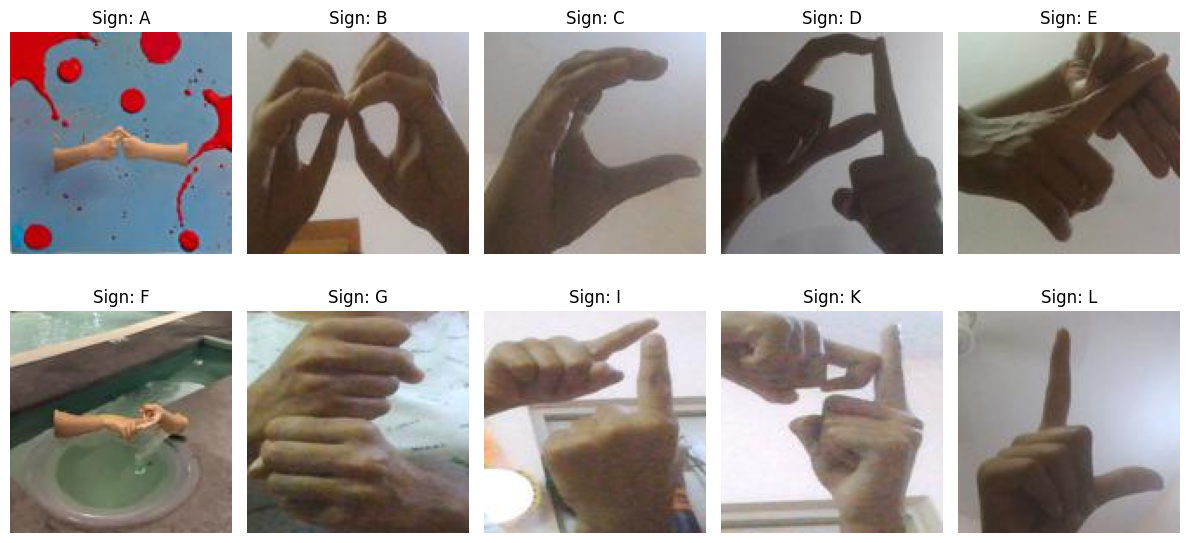

In [11]:

# Display one image from each of the first 10 classes
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for ax, class_name in zip(axes.flat, classes[:10]):

    # Get image files from the class folder
    class_folder = data_dir / class_name

    images = sorted([
        file for file in class_folder.iterdir()
        if file.suffix.lower() in image_extensions
    ])

    # Load the first image
    image = Image.open(images[0]).convert("RGB")

    # Display the image with its alphabet label
    ax.imshow(image)
    ax.set_title(f"Sign: {class_name}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [12]:
# Convert an image into a PyTorch tensor


# Select the first image from class A
class_folder = data_dir / "A"

image_path = sorted([
    file for file in class_folder.iterdir()
    if file.suffix.lower() in image_extensions
])[0]

# Load the image as RGB
image = Image.open(image_path).convert("RGB")

# Convert image into a NumPy array
image_array = np.array(image, dtype=np.float32)

# Normalize pixel values from 0–255 to 0–1
image_array = image_array / 255.0

# Convert NumPy array into PyTorch tensor
tensor = torch.from_numpy(image_array)

# Change shape from (Height, Width, Channels)
# to (Channels, Height, Width)
tensor = tensor.permute(2, 0, 1)

print("Original image shape:", image_array.shape)
print("PyTorch tensor shape:", tensor.shape)
print("Tensor data type:", tensor.dtype)
print("Minimum pixel value:", tensor.min().item())
print("Maximum pixel value:", tensor.max().item())


Original image shape: (128, 128, 3)
PyTorch tensor shape: torch.Size([3, 128, 128])
Tensor data type: torch.float32
Minimum pixel value: 0.0
Maximum pixel value: 0.9725490212440491


**Function	Purpose**

np.array()	Converts an image into numerical pixel values

/255.0	Normalizes pixel values

torch.from_numpy()	Creates a PyTorch tensor

permute(2, 0, 1)	Changes image dimensions to PyTorch's CNN format

tensor.shape	Displays tensor dimensions

In [13]:
# Tensor operations

# 1. Add batch dimension
# Shape: (3, H, W) -> (1, 3, H, W)
batch = tensor.unsqueeze(0)

# 2. Indexing: extract red color channel
red_channel = tensor[0]

# 3. Calculate average pixel intensity
mean_intensity = tensor.mean()

# 4. Tensor arithmetic: increase pixel brightness
# Clamp ensures values remain between 0 and 1
brighter_tensor = torch.clamp(tensor * 1.2, 0, 1)

print("Batch shape:", batch.shape)
print("Red channel shape:", red_channel.shape)
print("Average intensity:", mean_intensity.item())
print("Brighter tensor shape:", brighter_tensor.shape)


Batch shape: torch.Size([1, 3, 128, 128])
Red channel shape: torch.Size([128, 128])
Average intensity: 0.473038911819458
Brighter tensor shape: torch.Size([3, 128, 128])


In [14]:
# Define the neural network

import torch.nn as nn

# Define a Convolutional Neural Network
class ISLCNN(nn.Module):

    def __init__(self, num_classes):
        super().__init__()

        # First convolution block
        self.conv1 = nn.Conv2d(
            in_channels=3,     # RGB image
            out_channels=16,   # Learn 16 feature maps
            kernel_size=3,     # 3x3 filter
            padding=1         # Preserve height and width
        )

        # Second convolution block
        self.conv2 = nn.Conv2d(
            in_channels=16,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        # Activation and pooling layers
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2)

        # Reduce each feature map to one value
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))

        # Final classification layer
        self.fc = nn.Linear(32, num_classes)

    def forward(self, x):

        # Block 1: extract low-level features
        x = self.pool(self.relu(self.conv1(x)))

        # Block 2: extract more complex features
        x = self.pool(self.relu(self.conv2(x)))

        # Convert each feature map to one value
        x = self.avgpool(x)

        # Flatten: (batch, 32, 1, 1) -> (batch, 32)
        x = torch.flatten(x, start_dim=1)

        # Produce one score per alphabet class
        x = self.fc(x)

        return x


Important functions

**Function	Purpose**

nn.Module	Base class for PyTorch neural networks

nn.Conv2d()	Learns image features such as edges and shapes

nn.ReLU()	Introduces nonlinearity

nn.MaxPool2d()	Reduces image feature-map dimensions

nn.AdaptiveAvgPool2d()	Reduces each feature map to a fixed spatial size

nn.Linear()	Produces classification scores

forward()	Defines how data moves through the network

In [15]:
# Create the CNN


# Set random seed for reproducibility
torch.manual_seed(42)

# Select GPU if available, otherwise CPU
device = torch.device( "cuda" if torch.cuda.is_available() else "cpu")

# Number of classes comes from Exercise 1
num_classes = len(classes)

# Initialize the CNN
model = ISLCNN(num_classes=num_classes).to(device)

print("Device:", device)
print(model)

# Count trainable parameters
total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_params)


Device: cpu
ISLCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (avgpool): AdaptiveAvgPool2d(output_size=(1, 1))
  (fc): Linear(in_features=32, out_features=23, bias=True)
)
Trainable parameters: 5847


In [16]:
# Pass an actual image through the CNN


from torchvision import transforms

# Resize and convert image to a normalized tensor
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()  # Converts RGB image to CHW, values 0–1
])

# Use the PIL image from Exercise 1
input_tensor = transform(image)

# Add batch dimension: (3, 128, 128) -> (1, 3, 128, 128)
input_batch = input_tensor.unsqueeze(0).to(device)

# Evaluation mode disables training-specific behavior
model.eval()

# No gradients required for inference
with torch.no_grad():
    outputs = model(input_batch)

print("Input shape:", input_batch.shape)
print("Output shape:", outputs.shape)
print("Raw class scores:", outputs)


Input shape: torch.Size([1, 3, 128, 128])
Output shape: torch.Size([1, 23])
Raw class scores: tensor([[ 0.1185,  0.1901,  0.0313, -0.0448, -0.0649, -0.0531,  0.1173, -0.2116,
          0.1152, -0.0098, -0.1461, -0.0714, -0.0885, -0.1279,  0.0554, -0.0056,
         -0.0460, -0.0191, -0.0275,  0.1263, -0.1036, -0.0578, -0.0007]])


Predicted alphabet: B
Probability: 5.31%


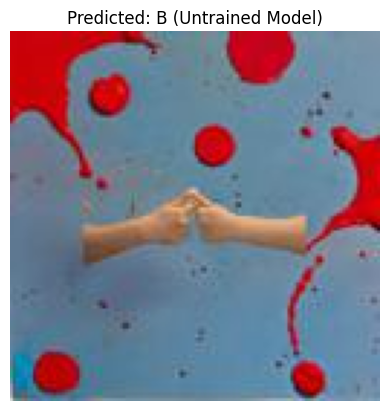

In [17]:
# Softmax and predicted alphabet


# Convert logits into probabilities
probabilities = torch.softmax(outputs, dim=1)

# Find class with highest probability
predicted_index = torch.argmax(probabilities, dim=1).item()

# Convert class index into alphabet label
predicted_class = classes[predicted_index]

# Get probability of the selected class
confidence = probabilities[0, predicted_index].item()

print("Predicted alphabet:", predicted_class)
print(f"Probability: {confidence:.2%}")

# Display the input image
plt.imshow(image)
plt.title(f"Predicted: {predicted_class} (Untrained Model)")
plt.axis("off")
plt.show()


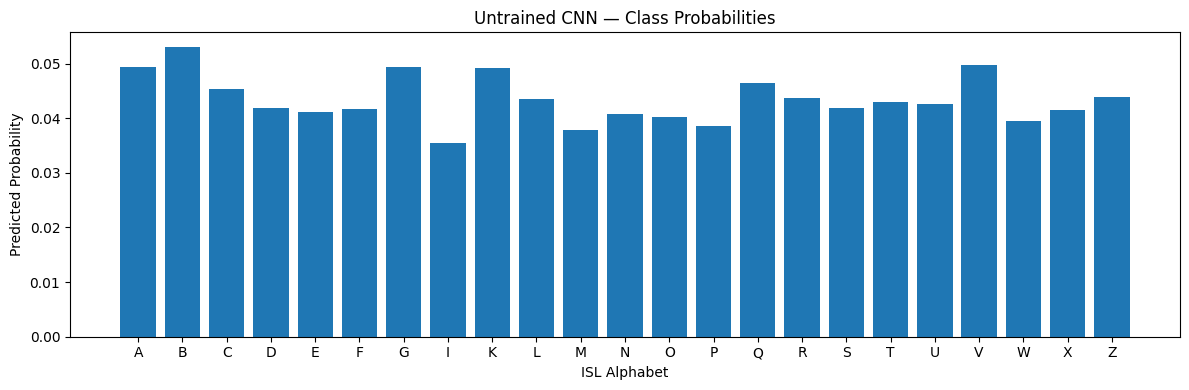

In [18]:
# Visualize the model's output scores


# Move probabilities to CPU for plotting
class_probs = probabilities.squeeze(0).cpu().numpy()

# Create a bar chart
plt.figure(figsize=(12, 4))

plt.bar(classes, class_probs)

plt.xlabel("ISL Alphabet")
plt.ylabel("Predicted Probability")
plt.title("Untrained CNN — Class Probabilities")

plt.tight_layout()
plt.show()


In [19]:
# Loss Functions & Backpropagation

#How can our CNN identify its prediction errors and calculate how its weights should change to recognize Indian Sign Language gestures more accurately?

# Cross-Entropy Loss


import torch.nn as nn

# CrossEntropyLoss is used for multiclass classification
criterion = nn.CrossEntropyLoss()

print("Loss function:", criterion)


Loss function: CrossEntropyLoss()


In [20]:
# Convert alphabet A into a numerical label


# Convert actual alphabet into numerical class index
actual_class = "A"

target_index = classes.index(actual_class)

# CrossEntropyLoss expects integer class indices
target = torch.tensor(
    [target_index],
    dtype=torch.long,
    device=device
)

print("Actual alphabet:", actual_class)
print("Target index:", target_index)
print("Target tensor:", target)
print("Target shape:", target.shape)


Actual alphabet: A
Target index: 0
Target tensor: tensor([0])
Target shape: torch.Size([1])


In [21]:
# Calculate prediction error

# Enable training mode
model.train()

# Clear any previously accumulated gradients
model.zero_grad()

# Forward propagation
# IMPORTANT: Do not use torch.no_grad() here
outputs = model(input_batch)

# Calculate prediction error
loss = criterion(outputs, target)

print("Output shape:", outputs.shape)
print("Target shape:", target.shape)
print("Cross-Entropy Loss:", loss.item())


Output shape: torch.Size([1, 23])
Target shape: torch.Size([1])
Cross-Entropy Loss: 3.0075650215148926


**What happened?**

1. model(input_batch) performs forward propagation.

2. criterion(outputs, target) compares predicted scores with the actual label.

3. loss.item() returns the scalar loss value.

In [22]:
# Calculate gradients


# Backpropagation computes gradients
loss.backward()

# Inspect gradients of the final classification layer
print("FC weight shape:", model.fc.weight.shape)

print("FC gradient shape:", model.fc.weight.grad.shape)

print(
    "Mean absolute gradient:",
    model.fc.weight.grad.abs().mean().item()
)

# Display a small sample of gradients
print(
    "First 5 gradients:",
    model.fc.weight.grad[0, :5]
)


FC weight shape: torch.Size([23, 32])
FC gradient shape: torch.Size([23, 32])
Mean absolute gradient: 0.0033432343043386936
First 5 gradients: tensor([-0.0022, -0.0977, -0.0071, -0.0458, -0.0245])


In [23]:
# Check whether gradients are flowing


# Inspect gradients for all trainable parameters
for name, parameter in model.named_parameters():

    if parameter.grad is not None:

        gradient_mean = parameter.grad.abs().mean().item()

        print(
            f"{name:20s} | "
            f"Shape: {str(tuple(parameter.shape)):18s} | "
            f"Mean Gradient: {gradient_mean:.8f}"
        )


conv1.weight         | Shape: (16, 3, 3, 3)      | Mean Gradient: 0.00910219
conv1.bias           | Shape: (16,)              | Mean Gradient: 0.01942107
conv2.weight         | Shape: (32, 16, 3, 3)     | Mean Gradient: 0.00297056
conv2.bias           | Shape: (32,)              | Mean Gradient: 0.04927622
fc.weight            | Shape: (23, 32)           | Mean Gradient: 0.00334323
fc.bias              | Shape: (23,)              | Mean Gradient: 0.08265983


In [24]:
# Backpropagation vs. weight updates


# Save current weights
weights_before = model.fc.weight.detach().clone()

# Gradients were calculated in Cell 15,
# but no optimizer step has been performed.

weights_after = model.fc.weight.detach().clone()

# Compare weights
weights_changed = not torch.equal(
    weights_before,
    weights_after
)

print("Weights changed:", weights_changed)
print("Gradients calculated:", model.fc.weight.grad is not None)


Weights changed: False
Gradients calculated: True


In [25]:
# Define image preprocessing


from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Image preprocessing
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

# Load images from your existing Google Drive folder
dataset = datasets.ImageFolder(
    root=str(data_dir),
    transform=transform
)

print("Total images:", len(dataset))
print("Classes:", dataset.classes)
print("Class mapping:", dataset.class_to_idx)


Total images: 702
Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Z']
Class mapping: {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'I': 7, 'K': 8, 'L': 9, 'M': 10, 'N': 11, 'O': 12, 'P': 13, 'Q': 14, 'R': 15, 'S': 16, 'T': 17, 'U': 18, 'V': 19, 'W': 20, 'X': 21, 'Z': 22}


**Function	Purpose**

ImageFolder()	Loads images from alphabet-labeled folders

Resize()	Ensures consistent image dimensions

ToTensor()	Converts images into normalized PyTorch tensors

class_to_idx	Maps alphabet labels to numerical indices

In [26]:
#Create training, validation, and test sets

# Get all image indices and their labels
indices = np.arange(len(dataset))
labels = np.array(dataset.targets)

# First split: 80% training, 20% temporary
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.20,
    stratify=labels,
    random_state=42
)

# Second split: 10% validation, 10% test
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=labels[temp_idx],
    random_state=42
)

# Create dataset subsets
train_dataset = Subset(dataset, train_idx)
val_dataset = Subset(dataset, val_idx)
test_dataset = Subset(dataset, test_idx)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))


Training images: 561
Validation images: 70
Testing images: 71


In [27]:
# Mini-batch processing


# Batch size: number of images processed together
batch_size = 16

# Training loader: shuffle images each epoch
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

# Validation loader: no shuffling required
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

# Test loader: reserved for Exercise 5
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

# Inspect one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)


Image batch shape: torch.Size([16, 3, 128, 128])
Label batch shape: torch.Size([16])


In [28]:
# Adam optimizer


import torch.optim as optim

# Reinitialize the CNN for a clean training run
torch.manual_seed(42)

model = ISLCNN(
    num_classes=len(dataset.classes)
).to(device)

# Multiclass classification loss
criterion = nn.CrossEntropyLoss()

# Adam updates the CNN's weights using gradients
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])


Optimizer: Adam
Learning rate: 0.001


**Operation	What it does**

optimizer.zero_grad()	Clears gradients from the previous batch

model(images)	Performs forward propagation

criterion(outputs, labels)	Calculates prediction error

loss.backward()	Computes gradients using backpropagation

optimizer.step()	Updates weights to reduce the loss

In [30]:

# Number of complete passes through training data
epochs = 10

# Store metrics for visualization
history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

for epoch in range(epochs):

    # -------------------------
    # TRAINING PHASE
    # -------------------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        # Move data to GPU or CPU
        images = images.to(device)
        labels = labels.to(device)

        # 1. Clear gradients from previous batch
        optimizer.zero_grad()

        # 2. Forward propagation
        outputs = model(images)

        # 3. Calculate classification loss
        loss = criterion(outputs, labels)

        # 4. Backpropagation
        loss.backward()

        # 5. Update model weights
        optimizer.step()

        # Accumulate sample-weighted loss
        running_loss += loss.item() * images.size(0)

        # Calculate training accuracy
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = correct / total

    # -------------------------
    # VALIDATION PHASE
    # -------------------------
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    # Disable gradients during validation
    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            # Forward pass only
            outputs = model(images)

            # Calculate validation loss
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = val_correct / val_total

    # Save metrics for each epoch
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    # Display progress
    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2%}"
    )


Epoch [1/10] | Train Loss: 3.1408 | Train Acc: 5.17% | Val Loss: 3.1351 | Val Acc: 5.71%
Epoch [2/10] | Train Loss: 3.1351 | Train Acc: 4.46% | Val Loss: 3.1354 | Val Acc: 4.29%
Epoch [3/10] | Train Loss: 3.1299 | Train Acc: 5.35% | Val Loss: 3.1362 | Val Acc: 4.29%
Epoch [4/10] | Train Loss: 3.1255 | Train Acc: 6.06% | Val Loss: 3.1374 | Val Acc: 1.43%
Epoch [5/10] | Train Loss: 3.1207 | Train Acc: 7.13% | Val Loss: 3.1371 | Val Acc: 2.86%
Epoch [6/10] | Train Loss: 3.1183 | Train Acc: 6.42% | Val Loss: 3.1408 | Val Acc: 1.43%
Epoch [7/10] | Train Loss: 3.1143 | Train Acc: 7.13% | Val Loss: 3.1393 | Val Acc: 2.86%
Epoch [8/10] | Train Loss: 3.1122 | Train Acc: 6.60% | Val Loss: 3.1413 | Val Acc: 5.71%
Epoch [9/10] | Train Loss: 3.1099 | Train Acc: 6.95% | Val Loss: 3.1455 | Val Acc: 4.29%
Epoch [10/10] | Train Loss: 3.1076 | Train Acc: 7.31% | Val Loss: 3.1437 | Val Acc: 2.86%


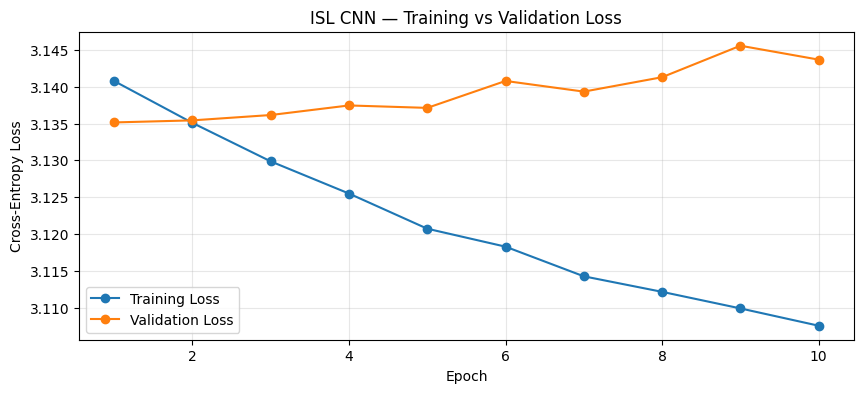

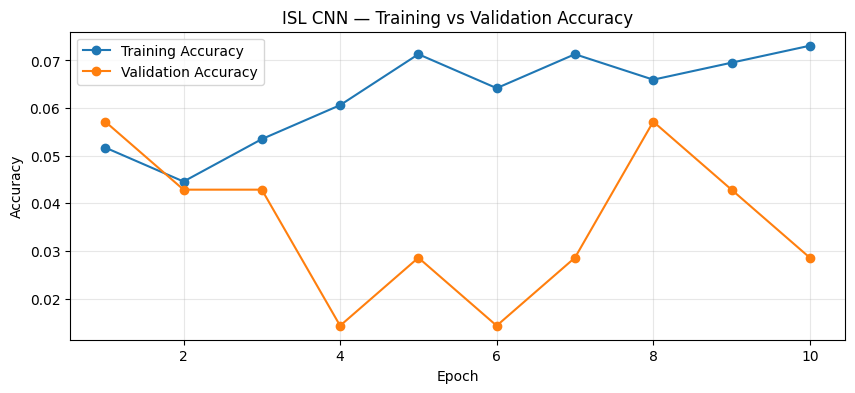

In [31]:
# Training and validation curves


# Create epoch numbers
epoch_numbers = range(1, epochs + 1)

# Plot training and validation loss
plt.figure(figsize=(10, 4))

plt.plot(
    epoch_numbers,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epoch_numbers,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("ISL CNN — Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Plot training and validation accuracy
plt.figure(figsize=(10, 4))

plt.plot(
    epoch_numbers,
    history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epoch_numbers,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ISL CNN — Training vs Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [32]:

# Select epoch with lowest validation loss
best_epoch = np.argmin(history["val_loss"])

print("Best epoch:", best_epoch + 1)

print(
    "Validation loss:",
    round(history["val_loss"][best_epoch], 4)
)

print(
    "Validation accuracy:",
    f"{history['val_accuracy'][best_epoch]:.2%}"
)

print(
    "Final training accuracy:",
    f"{history['train_accuracy'][-1]:.2%}"
)


Best epoch: 1
Validation loss: 3.1351
Validation accuracy: 5.71%
Final training accuracy: 7.31%


In [33]:
#How accurately can our trained CNN recognize Indian Sign Language alphabets from images it has never seen during training?

'''
Metric	Business meaning
Accuracy	What percentage of gestures were classified correctly?
Precision	When the model predicts an alphabet, how often is it correct?
Recall	How many actual examples of an alphabet does the model recognize?
F1-score	How well does the model balance precision and recall?
Confusion Matrix	Which alphabet gestures does the model confuse?
'''

#Generate test predictions


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Switch model to evaluation mode
model.eval()

# Store actual labels and predictions
y_true = []
y_pred = []

test_loss = 0.0
total_images = 0

# Disable gradient calculations during evaluation
with torch.no_grad():

    for images, labels in test_loader:

        # Move images and labels to GPU/CPU
        images = images.to(device)
        labels = labels.to(device)

        # Forward propagation
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Convert class scores into predicted class indices
        predictions = outputs.argmax(dim=1)

        # Accumulate loss across all test images
        test_loss += loss.item() * images.size(0)
        total_images += images.size(0)

        # Store results on CPU
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

# Calculate average test loss
test_loss = test_loss / total_images

print("Total test images:", total_images)
print("Average test loss:", round(test_loss, 4))


Total test images: 71
Average test loss: 3.1023


In [34]:
# Accuracy, Precision, Recall, F1-score


# Calculate overall test accuracy
accuracy = accuracy_score(y_true, y_pred)

# Macro-average treats every alphabet class equally
precision = precision_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

# Display evaluation metrics
metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-Score"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

display(metrics_df)

print(f"Test Accuracy: {accuracy:.2%}")
print(f"Macro F1-Score: {f1:.2%}")


,Metric,Score
0,Accuracy,0.070423
1,Macro Precision,0.005797
2,Macro Recall,0.045652
3,Macro F1-Score,0.010287


Test Accuracy: 7.04%
Macro F1-Score: 1.03%


In [35]:
# Classification report


# Generate per-class performance report
report = classification_report(
    y_true,
    y_pred,
    labels=range(len(dataset.classes)),
    target_names=dataset.classes,
    output_dict=True,
    zero_division=0
)

# Convert report into a DataFrame
report_df = pd.DataFrame(report).T

# Display metrics for each alphabet
display(
    report_df.loc[
        dataset.classes,
        ["precision", "recall", "f1-score", "support"]
    ].sort_values("f1-score")
)


,precision,recall,f1-score,support
A,0.000000,0.00,0.000000,2.0
C,0.000000,0.00,0.000000,4.0
D,0.000000,0.00,0.000000,4.0
F,0.000000,0.00,0.000000,2.0
I,0.000000,0.00,0.000000,3.0
G,0.000000,0.00,0.000000,3.0
L,0.000000,0.00,0.000000,4.0
K,0.000000,0.00,0.000000,4.0
O,0.000000,0.00,0.000000,4.0
P,0.000000,0.00,0.000000,3.0


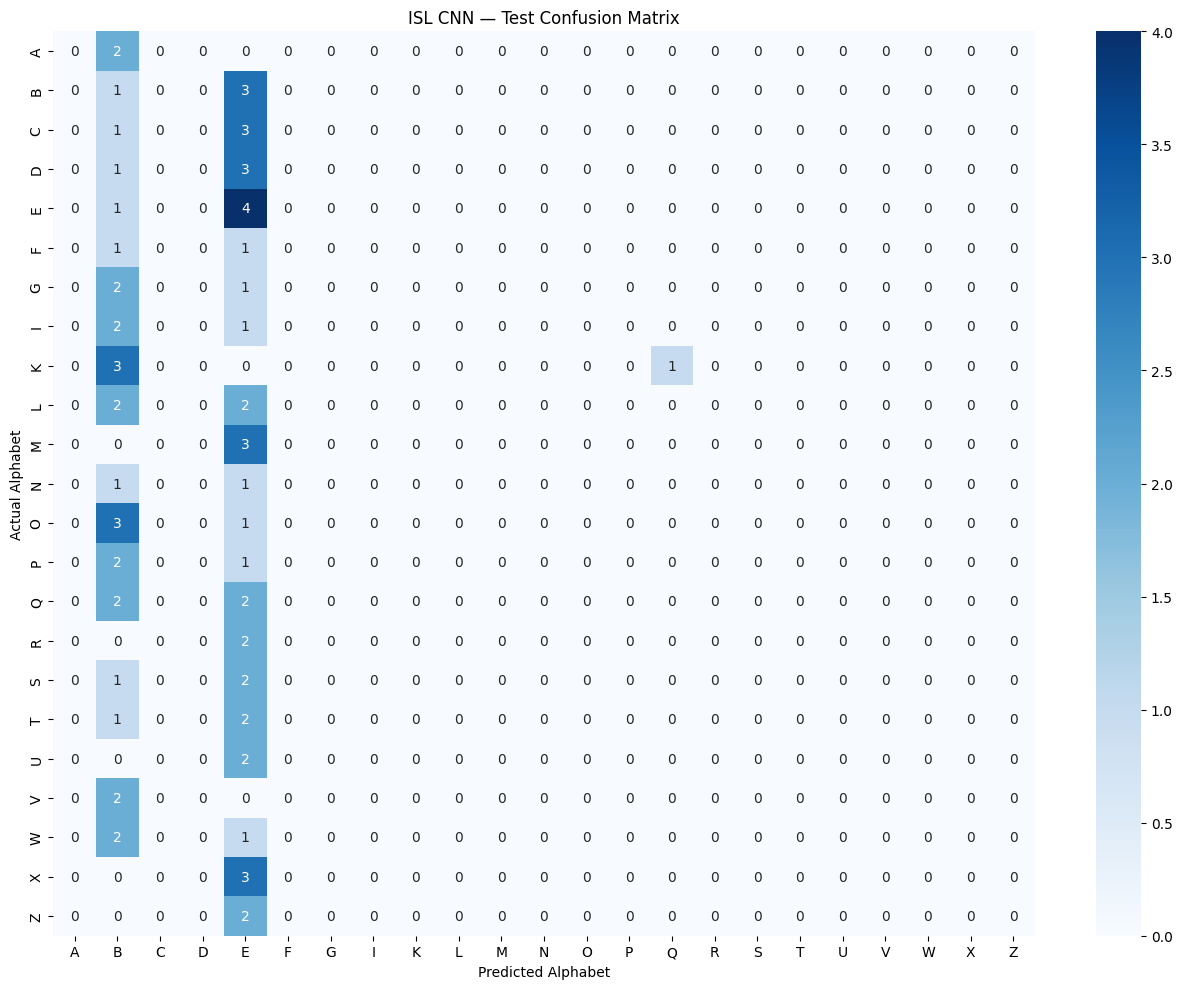

In [36]:
# Confusion matrix heatmap


import seaborn as sns

# Compute confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(dataset.classes))
)

# Visualize classification errors
plt.figure(figsize=(13, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=dataset.classes,
    yticklabels=dataset.classes
)

plt.xlabel("Predicted Alphabet")
plt.ylabel("Actual Alphabet")
plt.title("ISL CNN — Test Confusion Matrix")

plt.tight_layout()
plt.show()


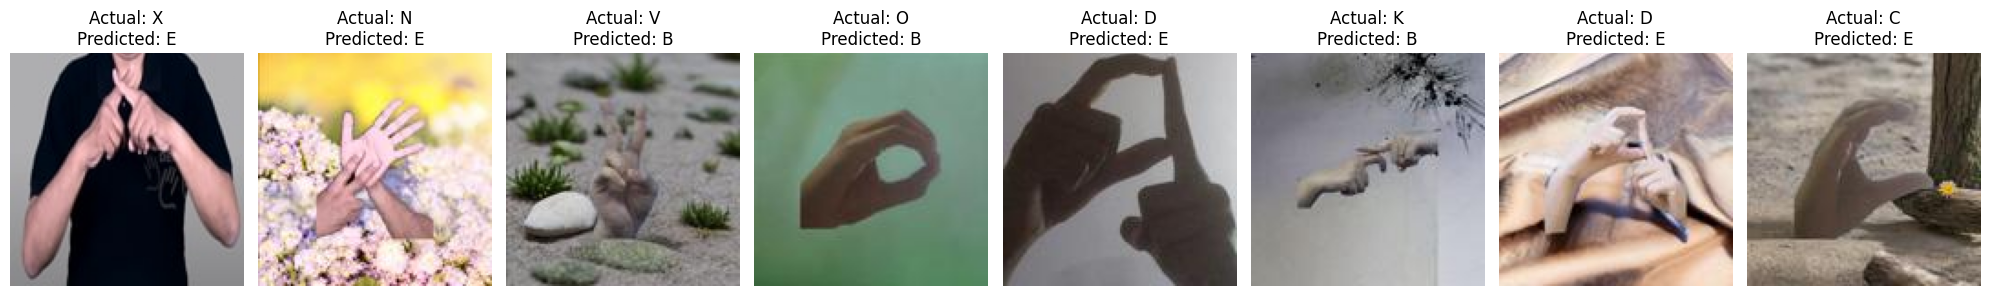

In [37]:
# Visualize misclassified images


# Collect incorrectly classified test samples
wrong_predictions = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        outputs = model(images.to(device))
        predictions = outputs.argmax(dim=1).cpu()

        # Compare actual and predicted labels
        for image, actual, predicted in zip(
            images, labels, predictions
        ):

            if actual.item() != predicted.item():

                wrong_predictions.append((
                    image,
                    actual.item(),
                    predicted.item()
                ))

# Display up to 8 incorrect predictions
num_examples = min(8, len(wrong_predictions))

if num_examples == 0:
    print("No incorrect predictions found in the test set.")

else:
    fig, axes = plt.subplots(
        1, num_examples,
        figsize=(2.5 * num_examples, 3)
    )

    axes = np.atleast_1d(axes)

    for ax, (image, actual, predicted) in zip(
        axes, wrong_predictions[:num_examples]
    ):

        # Convert CHW tensor into HWC image
        image = image.permute(1, 2, 0).numpy()

        ax.imshow(image)

        ax.set_title(
            f"Actual: {dataset.classes[actual]}\n"
            f"Predicted: {dataset.classes[predicted]}"
        )

        ax.axis("off")

    plt.tight_layout()
    plt.show()


In [38]:
# Analyze classification mistakes


# Create a copy of the confusion matrix
errors = cm.copy()

# Remove correct predictions (diagonal)
np.fill_diagonal(errors, 0)

# Collect confusion pairs
confusion_pairs = []

for actual_idx in range(len(dataset.classes)):

    for predicted_idx in range(len(dataset.classes)):

        count = errors[actual_idx, predicted_idx]

        if count > 0:

            confusion_pairs.append({
                "Actual": dataset.classes[actual_idx],
                "Predicted": dataset.classes[predicted_idx],
                "Mistakes": int(count)
            })

# Convert to DataFrame
confusion_df = pd.DataFrame(
    confusion_pairs,
    columns=["Actual", "Predicted", "Mistakes"]
)

# Display the most frequent errors
display(
    confusion_df.sort_values(
        "Mistakes",
        ascending=False
    ).head(10)
)


,Actual,Predicted,Mistakes
1,B,E,3
3,C,E,3
17,M,E,3
20,O,B,3
5,D,E,3
35,X,E,3
13,K,B,3
0,A,B,2
33,W,B,2
36,Z,E,2


In [39]:
#Generate an evidence-based evaluation summary


# Identify best and worst classes using F1-score
class_scores = report_df.loc[dataset.classes]

best_class = class_scores["f1-score"].idxmax()
worst_class = class_scores["f1-score"].idxmin()

# Count incorrect predictions
total_errors = sum(
    actual != predicted
    for actual, predicted in zip(y_true, y_pred)
)

print("ISL CNN — Evaluation Summary")
print("-" * 40)

print(f"Test images: {len(y_true)}")
print(f"Correct predictions: {len(y_true) - total_errors}")
print(f"Incorrect predictions: {total_errors}")

print(f"Test accuracy: {accuracy:.2%}")
print(f"Macro F1-score: {f1:.2%}")

print(f"Best F1 class: {best_class}")
print(f"Lowest F1 class: {worst_class}")

print("\nBusiness Conclusion:")

if accuracy >= 0.90 and f1 >= 0.90:
    print(
        "Strong preliminary performance on this test split. "
        "Validate on new signers and real-world images before deployment."
    )

elif accuracy >= 0.70 and f1 >= 0.70:
    print(
        "Promising baseline performance, but classification "
        "errors still require investigation."
    )

else:
    print(
        "Current performance is insufficient for reliable "
        "gesture recognition. Investigate model capacity, "
        "data quality, and training strategy."
    )


ISL CNN — Evaluation Summary
----------------------------------------
Test images: 71
Correct predictions: 5
Incorrect predictions: 66
Test accuracy: 7.04%
Macro F1-score: 1.03%
Best F1 class: E
Lowest F1 class: A

Business Conclusion:
Current performance is insufficient for reliable gesture recognition. Investigate model capacity, data quality, and training strategy.


In [40]:
# Model performance summary

# Compare final training, validation, and test metrics
performance_df = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Accuracy": [
        history["train_accuracy"][-1],
        history["val_accuracy"][-1],
        accuracy
    ],
    "Loss": [
        history["train_loss"][-1],
        history["val_loss"][-1],
        test_loss
    ]
})

# Display percentages for easier interpretation
display(
    performance_df.style.format({
        "Accuracy": "{:.2%}",
        "Loss": "{:.4f}"
    })
)

# Measure the generalization gap
generalization_gap = (
    history["train_accuracy"][-1]
    - history["val_accuracy"][-1]
)

print(f"Train–Validation Accuracy Gap: {generalization_gap:.2%}")


,Dataset,Accuracy,Loss
0,Training,7.31%,3.1076
1,Validation,2.86%,3.1437
2,Test,7.04%,3.1023


Train–Validation Accuracy Gap: 4.45%


Five lowest-performing alphabet classes:


,precision,recall,f1-score,support
A,0.0,0.0,0.0,2.0
C,0.0,0.0,0.0,4.0
D,0.0,0.0,0.0,4.0
F,0.0,0.0,0.0,2.0
I,0.0,0.0,0.0,3.0


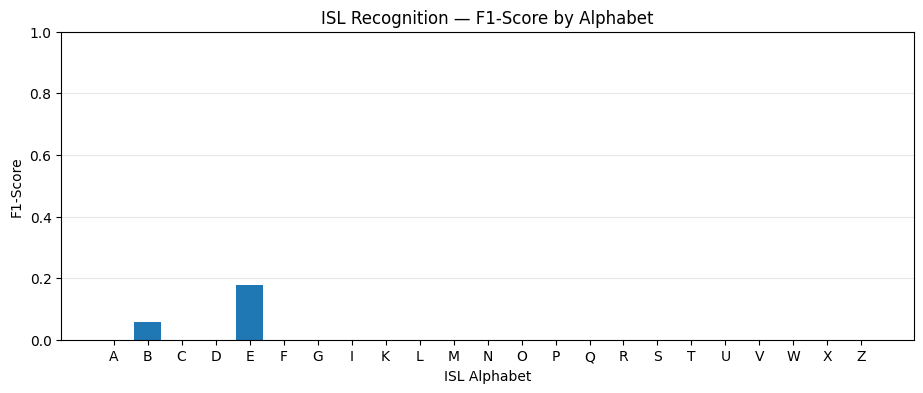

In [41]:
#Prioritize classes requiring improvement


# Retrieve per-class evaluation metrics
weak_classes = (
    report_df.loc[dataset.classes]
    [["precision", "recall", "f1-score", "support"]]
    .sort_values("f1-score")
    .head(5)
)

print("Five lowest-performing alphabet classes:")
display(weak_classes)

# Visualize per-class F1 scores
class_f1 = report_df.loc[dataset.classes, "f1-score"]

plt.figure(figsize=(11, 4))

plt.bar(dataset.classes, class_f1)

plt.xlabel("ISL Alphabet")
plt.ylabel("F1-Score")
plt.title("ISL Recognition — F1-Score by Alphabet")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()


In [43]:
#Save model weights and class mappings


# Save model in Google Drive
model_path = (
    "drive/MyDrive/Colab_Notebooks/A_DREAM_JOB/5_Deep_Learning/"
    "isl_pytorch_model.pth"
)

# Save weights and metadata required for future inference
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": dataset.classes,
    "image_size": (128, 128),
    "architecture": "ISLCNN",
    "num_classes": len(dataset.classes)
}, model_path)

print("Model saved successfully:", model_path)


Model saved successfully: drive/MyDrive/Colab_Notebooks/A_DREAM_JOB/5_Deep_Learning/isl_pytorch_model.pth


In [44]:
#Load the saved model


# Load the saved checkpoint
checkpoint = torch.load(
    model_path,
    map_location=device,
    weights_only=True
)

# Recreate the same CNN architecture
loaded_model = ISLCNN(
    num_classes=checkpoint["num_classes"]
).to(device)

# Restore learned parameters
loaded_model.load_state_dict(
    checkpoint["model_state_dict"]
)

# Set inference mode
loaded_model.eval()

print("Model loaded successfully.")
print("Supported alphabets:", checkpoint["class_names"])


Model loaded successfully.
Supported alphabets: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Z']


Actual alphabet: A
Predicted alphabet: B
Predicted probability: 5.82%


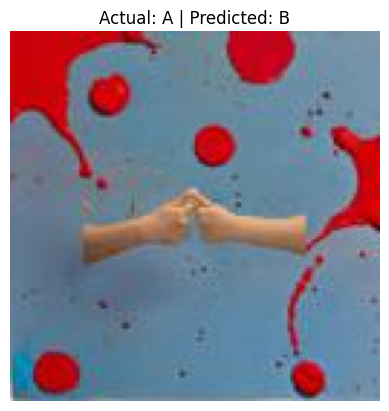

In [46]:

from PIL import Image
from torchvision import transforms

# 1. Select an actual image from your ISL dataset
image_path = sorted((data_dir / "A").glob("*.jpg"))[0]

# 2. Load image as PIL and convert to RGB
sample_image = Image.open(image_path).convert("RGB")

# 3. Apply the same preprocessing used during training
inference_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

# 4. Convert image into a batch tensor
sample_tensor = inference_transform(sample_image).unsqueeze(0).to(device)

# 5. Set loaded model to evaluation mode
loaded_model.eval()

# 6. Perform inference without calculating gradients
with torch.no_grad():
    logits = loaded_model(sample_tensor)

    # Convert logits into probabilities
    probabilities = torch.softmax(logits, dim=1)

    # Find the class with the highest probability
    predicted_idx = probabilities.argmax(dim=1).item()

# 7. Retrieve prediction
predicted_alphabet = checkpoint["class_names"][predicted_idx]
predicted_probability = probabilities[0, predicted_idx].item()

# 8. Display prediction
print("Actual alphabet: A")
print("Predicted alphabet:", predicted_alphabet)
print(f"Predicted probability: {predicted_probability:.2%}")

plt.imshow(sample_image)
plt.title(f"Actual: A | Predicted: {predicted_alphabet}")
plt.axis("off")
plt.show()
